## Clasificación Grupo 6

Integrantes: Mario Ibañez, Lorenzo Torres y Pablo Piqueras

Este archivo desarrollara el proceso completo de preprocesamiento, análisis exploratorio de datos (EDA) y clasificación mediante regresión logística. Tras esto evaluaremos la salida y en base a esto decidiremos el modelo

### Paso 1
Aquí voy a a hacer las cargas de los modulos y funciones que voy a necesitrar.

In [1]:
%pip install numpy pandas matplotlib seaborn scipy scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

df = pd.read_csv('Social_Network_Ads.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


---
# Parte 1 · Análisis exploratorio de datos (EDA)
*Responsable: Lorenzo Torres*

**Qué buscamos en este apartado.** Antes de entrenar nada queremos saber cuatro cosas:
1. Cómo son las variables (escala, forma de la distribución, valores raros).
2. Cuáles separan a los que compran de los que no, y de qué manera (lineal o no).
3. Si hace falta escalar antes de la regresión logística.
4. Qué combinaciones de variables merece la pena probar en la parte de modelos.

Trabajamos sobre una copia (`eda`) para no tocar el preprocesamiento de Mario.

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)   # avisos internos de seaborn/matplotlib
sns.set_theme(style='whitegrid', context='notebook')
PALETA = {0: '#4C72B0', 1: '#DD8452'}      # 0 = no compra (azul), 1 = compra (naranja)
MARCAS = {0: 'o', 1: '^'}                   # además del color, la forma distingue la clase

In [4]:
# Copia de trabajo SOLO para el EDA. La limpieza "oficial" (quitar User ID, codificar Gender)
# la hace Mario en el preprocesamiento; aquí la replicamos para poder analizar.
eda = df.drop(columns='User ID').copy()
eda['Gender_num'] = (eda['Gender'] == 'Male').astype(int)   # Male = 1, Female = 0
print('Dimensiones:', eda.shape)
eda.head()

Dimensiones: (400, 5)


,Gender,Age,EstimatedSalary,Purchased,Gender_num
0,Male,19,19000,0,1
1,Male,35,20000,0,1
2,Female,26,43000,0,0
3,Female,27,57000,0,0
4,Male,19,76000,0,1


## 2.1 Estadísticas descriptivas

In [5]:
desc = eda[['Age', 'EstimatedSalary']].describe().T
desc['asimetría'] = eda[['Age', 'EstimatedSalary']].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
Age,400.0,37.66,10.48,18.0,29.75,37.0,46.0,60.0,0.23
EstimatedSalary,400.0,69742.50,34096.96,15000.0,43000.00,70000.0,88000.0,150000.0,0.50


**Qué vemos:**
- `Age` va de 18 a 60 años (media ≈ 37,7) y su distribución es casi simétrica (asimetría 0,23).
- `EstimatedSalary` va de 15.000 a 150.000 (media ≈ 69.700) y tiene algo de cola a la derecha (asimetría 0,50). No es tan sesgada como para pedir una transformación logarítmica.
- No aparecen valores imposibles: no hay edades ni salarios negativos o fuera de rango.

Ahora separamos por clase:

In [6]:
eda.groupby('Purchased')[['Age', 'EstimatedSalary']].describe().T.round(1)

Purchased                     0         1
Age             count     257.0     143.0
                mean       32.8      46.4
                std         8.0       8.6
                min        18.0      27.0
                25%        26.0      39.5
                50%        34.0      47.0
                75%        38.0      53.0
                max        59.0      60.0
EstimatedSalary count     257.0     143.0
                mean    60544.7   86272.7
                std     24351.6   42064.2
                min     15000.0   20000.0
                25%     44000.0   41000.0
                50%     61000.0   90000.0
                75%     77000.0  122500.0
                max    141000.0  150000.0

**Interpretación de la tabla por clase:**
- **Edad.** Quien compra tiene de media 46,4 años y quien no, 32,8. La diferencia es de unos 13,6 años. Ningún menor de 27 años ha comprado.
- **Salario.** La media de los compradores es más alta (86.300 frente a 60.500), pero su dispersión casi dobla la de los no compradores (desviación típica 42.000 frente a 24.400). Lo más llamativo es que **el 25 % de los compradores gana menos de 41.000**, es decir, menos que el primer cuartil de los no compradores (44.000). Por tanto, los compradores no son un único grupo de "gente con dinero": hay compradores con salario bajo. Lo comprobamos en los gráficos.

## 2.2 Histogramas y boxplots por clase

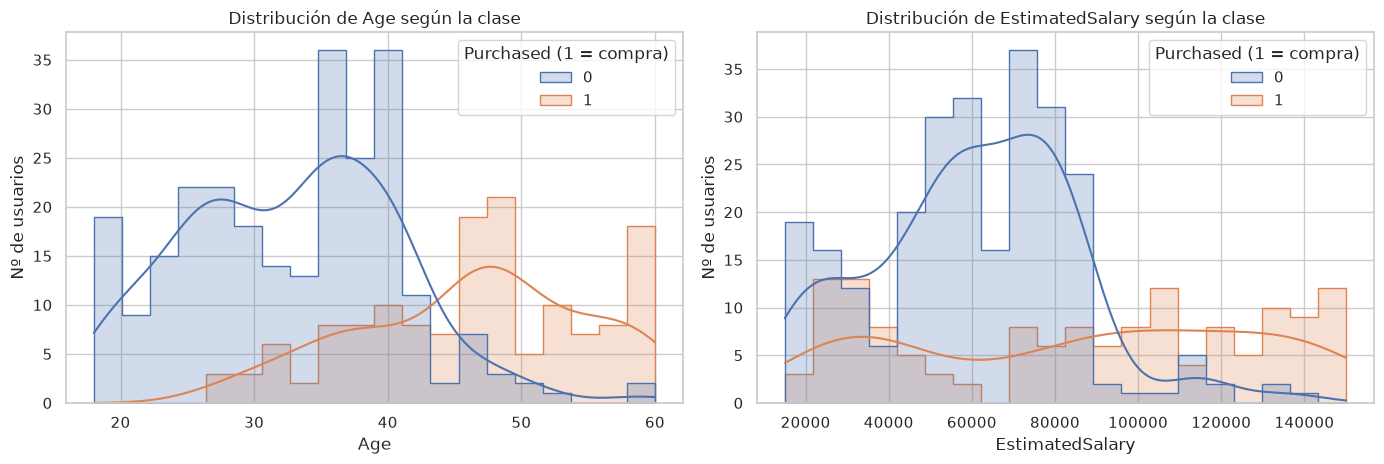

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col in zip(axes, ['Age', 'EstimatedSalary']):
    sns.histplot(data=eda, x=col, hue='Purchased', palette=PALETA, bins=20,
                 kde=True, element='step', ax=ax)
    ax.set_title(f'Distribución de {col} según la clase')
    ax.set_ylabel('Nº de usuarios')
    ax.get_legend().set_title('Purchased (1 = compra)')
axes[1].ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

**Histogramas:**
- **Age.** Las dos distribuciones están bastante desplazadas. Los no compradores se concentran por debajo de los 42 años y los compradores por encima de los 45. La zona de solape (entre 35 y 45 años, aproximadamente) es donde el modelo lo tendrá más difícil.
- **EstimatedSalary.** Los no compradores forman un bloque entre 40.000 y 90.000. Los compradores se reparten en **dos zonas**: una por encima de 90.000 y otra por debajo de 50.000. En la franja intermedia casi no hay compradores. Esto ya nos dice que la relación entre salario y compra **no es monótona**. Un modelo que solo use el salario de forma lineal asumirá que "más salario = más probabilidad", y eso no se cumple para los salarios bajos.

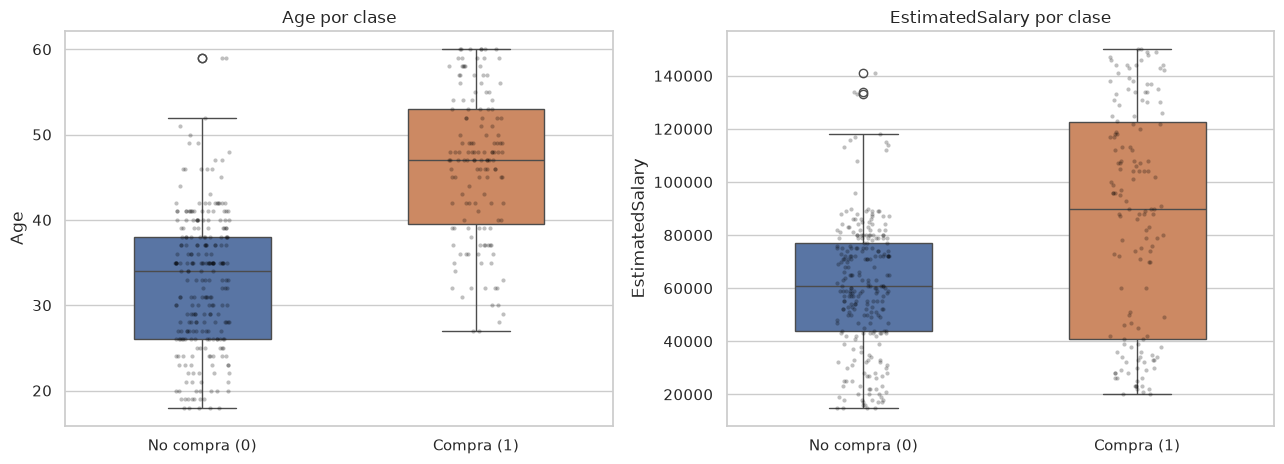

Age              Mann-Whitney U = 31921   p-valor = 2.13e-34
EstimatedSalary  Mann-Whitney U = 25168   p-valor = 8.84e-10


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col in zip(axes, ['Age', 'EstimatedSalary']):
    sns.boxplot(data=eda, x='Purchased', y=col, hue='Purchased', palette=PALETA,
                legend=False, width=0.5, ax=ax)
    sns.stripplot(data=eda, x='Purchased', y=col, color='black', alpha=0.25, size=3, ax=ax)
    ax.set_xticks([0, 1], ['No compra (0)', 'Compra (1)'])
    ax.set_xlabel('')
    ax.set_title(f'{col} por clase')
axes[1].ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

# Contraste no paramétrico (no asumimos normalidad): ¿difieren las distribuciones entre clases?
for col in ['Age', 'EstimatedSalary']:
    u, p = stats.mannwhitneyu(eda.loc[eda.Purchased == 1, col], eda.loc[eda.Purchased == 0, col])
    print(f'{col:16s} Mann-Whitney U = {u:.0f}   p-valor = {p:.2e}')

**Boxplots y contraste estadístico:**
- En `Age` las cajas casi no se solapan: la mediana es 47 en compradores y 34 en no compradores.
- En `EstimatedSalary` la caja de los compradores es muy ancha (de 41.000 a 122.500) y su parte baja se mete de lleno en la de los no compradores.
- Los puntos que el boxplot marca como "atípicos" (no compradores con salario > 120.000, por ejemplo) son pocos y plausibles. **No los consideramos errores** y no los eliminamos.
- La prueba de Mann-Whitney (elegida porque no exige normalidad) confirma que las dos variables difieren entre clases (p < 0,001 en ambas). La edad separa mucho más que el salario (p ≈ 10⁻³⁴ frente a 10⁻⁹).

## 2.3 Gender frente a Purchased

Conteos:
 Purchased    0    1  All
Gender                  
Female     127   77  204
Male       130   66  196
All        257  143  400 

% de compra dentro de cada género:
 Purchased     0     1
Gender               
Female     62.3  37.7
Male       66.3  33.7 

Chi-cuadrado = 0.555  (gl = 1)   p-valor = 0.456


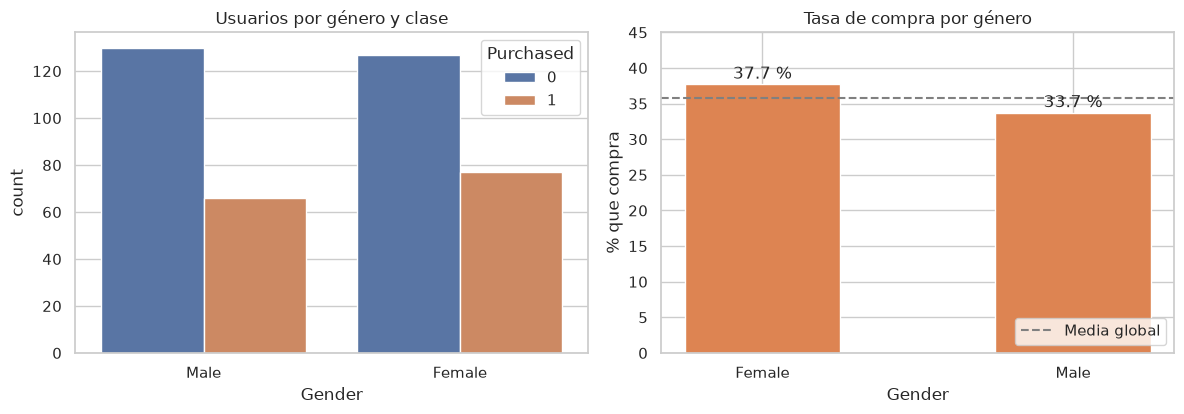

In [9]:
tabla = pd.crosstab(eda['Gender'], eda['Purchased'], margins=True)
tabla_pct = pd.crosstab(eda['Gender'], eda['Purchased'], normalize='index').mul(100).round(1)
print('Conteos:\n', tabla, '\n')
print('% de compra dentro de cada género:\n', tabla_pct, '\n')

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(eda['Gender'], eda['Purchased']))
print(f'Chi-cuadrado = {chi2:.3f}  (gl = {dof})   p-valor = {p:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.countplot(data=eda, x='Gender', hue='Purchased', palette=PALETA, ax=axes[0])
axes[0].set_title('Usuarios por género y clase')
axes[0].get_legend().set_title('Purchased')
axes[1].bar(tabla_pct.index, tabla_pct[1], color=PALETA[1], width=0.5)
axes[1].set_ylim(0, 45)
axes[1].axhline(eda['Purchased'].mean() * 100, ls='--', color='grey', label='Media global')
axes[1].set_ylabel('% que compra'); axes[1].set_title('Tasa de compra por género')
axes[1].set_xlabel('Gender'); axes[1].legend(loc='lower right')
for i, v in enumerate(tabla_pct[1]):
    axes[1].text(i, v + 0.8, f'{v:.1f} %', ha='center')
plt.tight_layout()
plt.show()

**Interpretación:**
- Compra el 37,7 % de las mujeres y el 33,7 % de los hombres: 4 puntos de diferencia.
- El test chi-cuadrado da **p = 0,456**. No hay evidencia de que la compra dependa del género, y una diferencia de este tamaño puede salir por azar con 400 usuarios.
- **Conclusión:** `Gender` aporta poca o ninguna información. Aun así, la probaremos en un modelo (M4) para comprobarlo de forma empírica, sin descartarla solo por el EDA.

## 2.5 Matriz de correlación
Mostramos Pearson (relación lineal) y Spearman (relación monótona, basada en rangos) para ver si cambian las conclusiones.

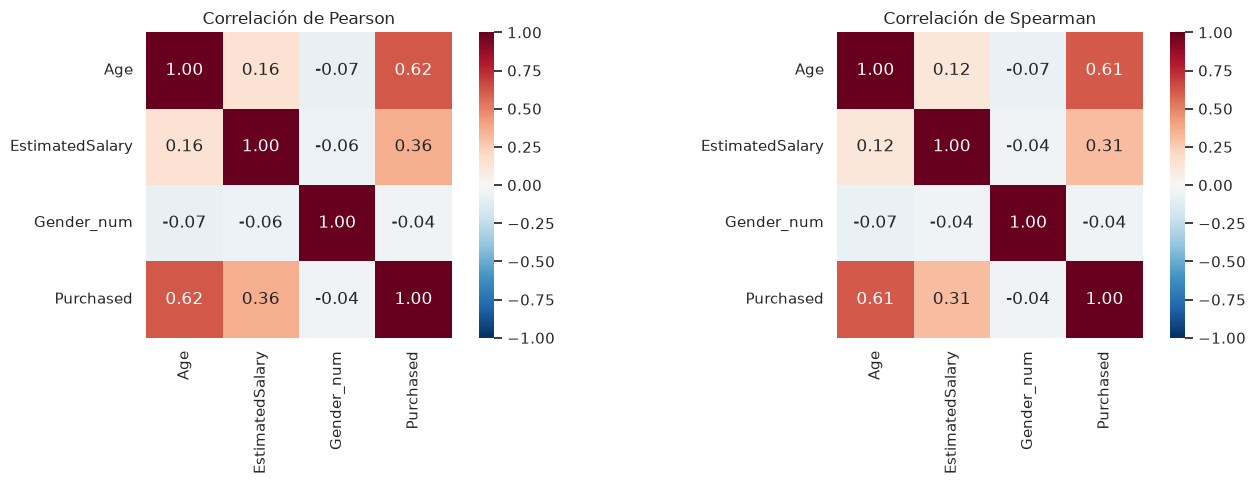

,corr. Pearson con Purchased
Age,0.622
EstimatedSalary,0.362
Gender_num,-0.042


In [10]:
num = eda[['Age', 'EstimatedSalary', 'Gender_num', 'Purchased']]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metodo in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(num.corr(method=metodo), annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(f'Correlación de {metodo.capitalize()}')
plt.tight_layout()
plt.show()
num.corr()['Purchased'].drop('Purchased').round(3).to_frame('corr. Pearson con Purchased')

**Interpretación:**
- `Age` es la variable más relacionada con la compra (r = 0,62).
- `EstimatedSalary` tiene una relación moderada (r = 0,36).
- `Gender` prácticamente no tiene relación (r = −0,04), lo que coincide con el chi-cuadrado.
- **Multicolinealidad:** la correlación entre `Age` y `EstimatedSalary` es solo de 0,16, así que podemos meter las dos en el mismo modelo sin problemas de redundancia.
- **Ojo con el salario:** la correlación solo mide relación lineal (Pearson) o monótona (Spearman). Hemos visto que la relación del salario con la compra tiene forma de U en algunas edades, así que el 0,36 **infravalora** su utilidad real cuando se combina con la edad. Por eso no basta con mirar la matriz.

## 2.6 Pairplot coloreado por Purchased

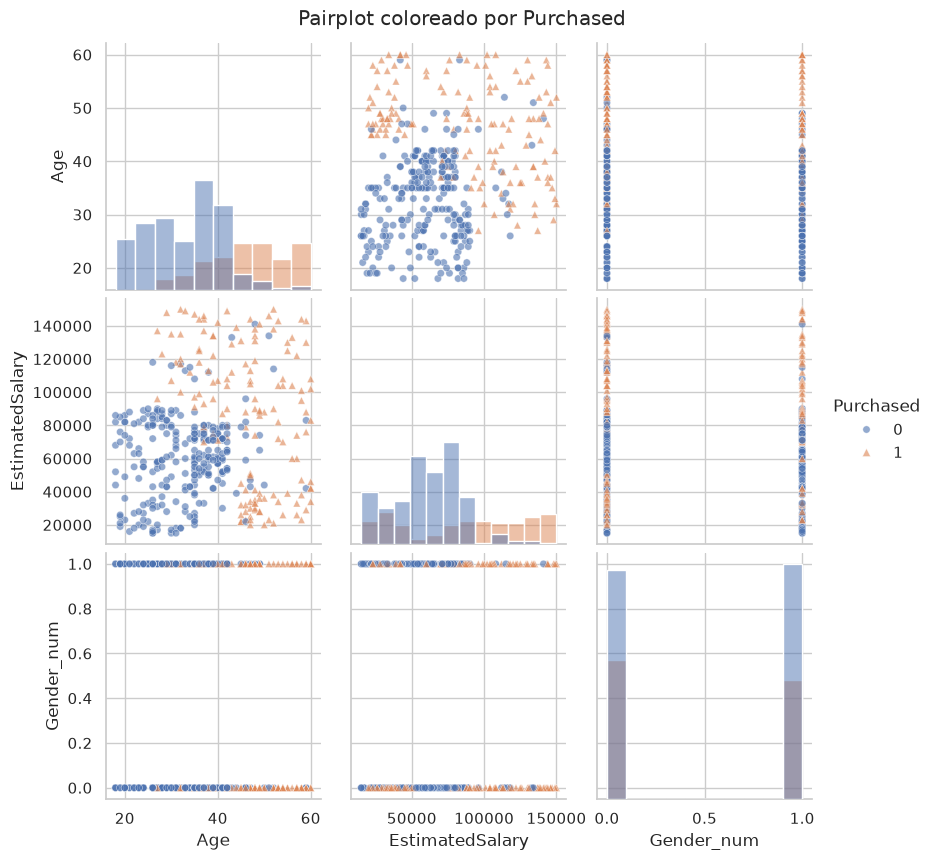

In [11]:
g = sns.pairplot(eda[['Age', 'EstimatedSalary', 'Gender_num', 'Purchased']],
                 hue='Purchased', palette=PALETA, markers=['o', '^'],
                 diag_kind='hist', plot_kws={'alpha': 0.6, 's': 28}, height=2.8)
g.figure.suptitle('Pairplot coloreado por Purchased', y=1.02)
plt.show()

**Interpretación:**
- El panel **Age vs EstimatedSalary** es el más revelador. Los no compradores (círculos azules) se agrupan en la zona de "joven y salario bajo o medio". Los compradores (triángulos naranjas) los rodean por arriba (salario alto) y por la derecha (edad alta), y hay un grupo claro de compradores en la esquina "mayor de 45 y salario < 50.000". La forma de la región azul es **curva, como una esquina redondeada**, y no una recta.
- Los paneles con `Gender_num` muestran dos líneas (0 y 1) con la misma mezcla de colores. El género no separa las clases.

## 2.7 ¿Hace falta escalar?

In [12]:
escalas = eda[['Age', 'EstimatedSalary', 'Gender_num']].agg(['min', 'max', 'mean', 'std']).T
escalas['rango'] = escalas['max'] - escalas['min']
print('Escala de las variables originales:')
print(escalas.round(1), '\n')

# Si además creamos términos polinómicos (lo que haremos en la parte 2), la diferencia se dispara:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)
Xp = poly.fit_transform(eda[['Age', 'EstimatedSalary']])
pd.DataFrame({'máximo': Xp.max(axis=0), 'desv. típica': Xp.std(axis=0)},
             index=poly.get_feature_names_out()).map(lambda v: f'{v:,.0f}')

Escala de las variables originales:
                     min       max     mean      std     rango
Age                 18.0      60.0     37.7     10.5      42.0
EstimatedSalary  15000.0  150000.0  69742.5  34097.0  135000.0
Gender_num           0.0       1.0      0.5      0.5       1.0 



,máximo,desv. típica
Age,60,10
EstimatedSalary,"150,000","34,054"
Age^2,"3,600",823
Age EstimatedSalary,"8,437,000","1,659,286"
EstimatedSalary^2,"22,500,000,000","5,488,812,521"


**Las escalas son muy distintas:** la edad tiene un rango de 42 y el salario de 135.000 (unas 3.200 veces más). Y al crear términos polinómicos la diferencia se dispara: `EstimatedSalary²` llega a 2,25·10¹⁰, frente a 3.600 de `Age²`.

¿Por qué importa esto en una regresión logística? Hay que matizar. **En teoría, una logística sin regularización da las mismas predicciones con o sin escalado**, porque los coeficientes se ajustan a cualquier escala. En la práctica sí importa, por tres razones:
1. `LogisticRegression` de scikit-learn aplica por defecto **regularización L2** (`C = 1`). La penalización castiga por igual a todos los coeficientes, y su tamaño depende de la unidad de cada variable. Sin escalar, el modelo penaliza de forma muy distinta a la edad y al salario.
2. El optimizador (`lbfgs`) **converge peor** cuando las variables tienen magnitudes tan diferentes.
3. Con las variables estandarizadas, los **coeficientes son comparables** entre sí, lo que ayuda a interpretarlos.

En lugar de quedarnos en la teoría, lo comprobamos con validación cruzada **solo sobre Train**. Para ello replicamos el split de Mario (estratificado, 25 % Test, `random_state = 42`).

In [13]:
from sklearn.model_selection import train_test_split

# Réplica del split de Mario (01_preprocesamiento). Si él usa otros valores, cambiarlos aquí.
TEST_SIZE, SEED = 0.25, 42
datos = df.drop(columns='User ID').copy()
datos['Gender'] = (datos['Gender'] == 'Male').astype(int)   # Male = 1, Female = 0
X = datos[['Gender', 'Age', 'EstimatedSalary']]
y = datos['Purchased']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print(f'% compra  Train = {y_train.mean():.3f}   Test = {y_test.mean():.3f}')

Train: (300, 3)  Test: (100, 3)
% compra  Train = 0.357   Test = 0.360


In [14]:
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.exceptions import ConvergenceWarning

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
variables = ['Age', 'EstimatedSalary']
casos = {
    'Lineal SIN escalar': Pipeline([('logreg', LogisticRegression())]),
    'Lineal CON StandardScaler': Pipeline([('scaler', StandardScaler()), ('logreg', LogisticRegression())]),
    'Grado 2 SIN escalar': Pipeline([('poly', PolynomialFeatures(2, include_bias=False)),
                                     ('logreg', LogisticRegression())]),
    'Grado 2 CON StandardScaler': Pipeline([('poly', PolynomialFeatures(2, include_bias=False)),
                                            ('scaler', StandardScaler()), ('logreg', LogisticRegression())]),
}
filas = []
for nombre, modelo in casos.items():
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        r = cross_validate(modelo, X_train[variables], y_train, cv=cv5, scoring=['accuracy', 'recall'])
    filas.append({'modelo': nombre,
                  'accuracy CV': r['test_accuracy'].mean(),
                  'recall CV': r['test_recall'].mean(),
                  'avisos de no convergencia': sum(issubclass(a.category, ConvergenceWarning) for a in avisos)})
pd.DataFrame(filas).set_index('modelo').round(3)

,accuracy CV,recall CV,avisos de no convergencia
modelo,,,
Lineal SIN escalar,0.840,0.693,0
Lineal CON StandardScaler,0.843,0.693,0
Grado 2 SIN escalar,0.850,0.683,2
Grado 2 CON StandardScaler,0.883,0.805,0


**Resultado de la comprobación (CV de 5 folds sobre Train):**
- En el **modelo lineal**, escalar casi no cambia nada (accuracy 0,840 frente a 0,843, mismo recall). Con solo dos variables, el optimizador se las apaña.
- En el **modelo de grado 2**, escalar sí marca la diferencia. Sin escalar aparecen avisos de **no convergencia** y el modelo rinde peor: accuracy 0,850 frente a 0,883 y, sobre todo, **recall 0,683 frente a 0,805**. Es decir, sin escalar se le escapan muchos más compradores.

**Decisión:** aplicamos `StandardScaler` siempre. Elegimos estandarización (media 0, desviación 1) en vez de MinMax porque no hay valores extremos que distorsionen la media y porque es lo habitual con regularización L2. El escalador **se ajusta solo con Train y va dentro del Pipeline**, después de `PolynomialFeatures`. Así se escalan también los términos polinómicos y, en la validación cruzada, cada fold se escala con sus propios datos de entrenamiento, sin fuga de información.

> Matiz al argumento inicial de "el salario llega a 150.000 y la edad a 60, así que hay que escalar": la conclusión es correcta, pero la razón de peso es la regularización y la convergencia, sobre todo cuando añadimos términos polinómicos.

## 2.8 Conclusiones del EDA y propuesta de modelos (para Pablo)

**Variables que influyen en la compra:**

| Variable | ¿Influye? | Evidencia |
|---|---|---|
| `Age` | **Sí, es la más importante** | r = 0,62; 13,6 años de diferencia media; Mann-Whitney p ≈ 10⁻³⁴ |
| `EstimatedSalary` | **Sí, pero de forma no lineal** | r = 0,36; compradores en dos zonas (salario bajo con edad alta y salario alto); forma de U en 41-50 años |
| `Gender` | **Prácticamente no** | 37,7 % frente a 33,7 %; chi-cuadrado p = 0,456; r = −0,04 |
| `User ID` | No (es un identificador) | Se elimina en el preprocesamiento |

**Combinaciones que proponemos probar, y por qué:**

| Modelo | Variables | Qué queremos comprobar |
|---|---|---|
| M1 | `Age` | Cuánto explica la mejor variable por sí sola (modelo de referencia) |
| M2 | `EstimatedSalary` | Cuánto explica el salario sin la edad |
| M3 | `Age + EstimatedSalary` | Modelo lineal base con las dos variables útiles |
| M4 | `Age + EstimatedSalary + Gender` | Confirmar empíricamente que `Gender` no aporta |
| M5 | M3 + `Age·Salary` | Si la interacción recoge que el efecto del salario depende de la edad |
| M6 | Polinómico de grado 2 (Age, Salary) | Frontera curva: añade `Age²` y `Salary²` para la forma de U |
| M7 | Polinómico de grado 3 (Age, Salary) | Si más flexibilidad ayuda o empieza a sobreajustar |

**Hipótesis que dejamos planteada:** los modelos con términos no lineales (M5-M7) deberían superar a los lineales (M3, M4). Con 300 observaciones de entrenamiento, el grado 3 puede empezar a sobreajustar. La validación cruzada (parte de Pablo) es la que tiene que decidirlo.

---
# Parte 2 · Gráficos de las predicciones en Train y fronteras de decisión
*Responsable: Lorenzo Torres*

**Objetivo:** ver *dónde* acierta y *dónde* falla cada modelo, más allá de un número de accuracy.

> **Nota de coordinación.** Los modelos de esta celda reproducen los que entrena Pablo en su apartado (mismo esquema `PolynomialFeatures → StandardScaler → LogisticRegression` y mismas variables). Así este apartado se puede ejecutar por sí solo. Al montar el informe final basta con sustituir el diccionario `modelos` por el de Pablo. La comparación con validación cruzada, Test y matrices de confusión está en su apartado. Aquí mostramos las métricas de Train solo para acompañar a los gráficos.

In [15]:
from sklearn.metrics import accuracy_score, recall_score

def crear_pipeline(grado=1, solo_interaccion=False):
    """PolynomialFeatures -> StandardScaler -> LogisticRegression (esquema acordado con Pablo)."""
    return Pipeline([
        ('poly', PolynomialFeatures(degree=grado, interaction_only=solo_interaccion, include_bias=False)),
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(max_iter=1000)),
    ])

# PROVISIONAL: mismos modelos que propone Pablo. Cuando tengamos su notebook,
# basta con sustituir este diccionario por el suyo (nombre -> (variables, pipeline)).
modelos = {
    'M1: Age':                       (['Age'],                              crear_pipeline(1)),
    'M2: EstimatedSalary':           (['EstimatedSalary'],                  crear_pipeline(1)),
    'M3: Age + Salary':              (['Age', 'EstimatedSalary'],           crear_pipeline(1)),
    'M4: Age + Salary + Gender':     (['Age', 'EstimatedSalary', 'Gender'], crear_pipeline(1)),
    'M5: Age + Salary + Age·Salary': (['Age', 'EstimatedSalary'],           crear_pipeline(2, solo_interaccion=True)),
    'M6: Polinómico grado 2':        (['Age', 'EstimatedSalary'],           crear_pipeline(2)),
    'M7: Polinómico grado 3':        (['Age', 'EstimatedSalary'],           crear_pipeline(3)),
}

resumen = []
for nombre, (vars_, modelo) in modelos.items():
    modelo.fit(X_train[vars_], y_train)
    pred = modelo.predict(X_train[vars_])
    resumen.append({'modelo': nombre,
                    'accuracy Train': accuracy_score(y_train, pred),
                    'recall Train': recall_score(y_train, pred),
                    'errores en Train': int((pred != y_train).sum())})
resumen = pd.DataFrame(resumen).set_index('modelo')
resumen.round(3)

,accuracy Train,recall Train,errores en Train
modelo,,,
M1: Age,0.830,0.654,51
M2: EstimatedSalary,0.783,0.477,65
M3: Age + Salary,0.847,0.710,46
M4: Age + Salary + Gender,0.853,0.710,44
M5: Age + Salary + Age·Salary,0.863,0.748,41
M6: Polinómico grado 2,0.883,0.804,35
M7: Polinómico grado 3,0.897,0.850,31


Las métricas de Train mejoran a medida que añadimos flexibilidad (de 46 errores en M3 a 31 en M7). **Esto es lo esperable y no demuestra que M7 sea mejor**: un modelo más flexible siempre se ajusta mejor a los datos con los que se entrena. Si la mejora es real o es sobreajuste lo dirán la validación cruzada y Test.

### Funciones de dibujo
- El fondo de color es la **probabilidad de compra** que estima el modelo (azul = baja, rojo = alta). La línea negra es la **frontera de decisión** (p = 0,5).
- Los puntos son los usuarios de Train, con su **clase real** indicada por color y forma (círculo azul = no compra, triángulo naranja = compra).
- Los usuarios **mal clasificados** llevan un anillo negro.
- Los ejes están en unidades originales (años y euros). Como el escalado va dentro del pipeline, el modelo lo aplica él solo al predecir.

In [16]:
from matplotlib.lines import Line2D

EDAD_LIM = (16, 62)
SAL_LIM = (10_000, 155_000)

def leyenda_puntos(ax, loc='upper left'):
    elementos = [
        Line2D([], [], marker='o', ls='', color=PALETA[0], label='Real: no compra'),
        Line2D([], [], marker='^', ls='', color=PALETA[1], label='Real: compra'),
        Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor='black',
               markeredgewidth=1.8, markersize=10, label='Mal clasificado'),
        Line2D([], [], color='black', lw=2, label='Frontera (p = 0,5)'),
    ]
    ax.legend(handles=elementos, loc=loc, fontsize=8, framealpha=0.9)

def dibujar_puntos(ax, Xp, yp, pred, x_col='Age', y_col='EstimatedSalary'):
    for clase in (0, 1):
        m = (yp == clase).values
        ax.scatter(Xp.loc[m, x_col], Xp.loc[m, y_col], c=PALETA[clase], marker=MARCAS[clase],
                   edgecolor='white', linewidth=0.5, s=34, zorder=3)
    mal = (pred != yp.values)
    ax.scatter(Xp.loc[mal, x_col], Xp.loc[mal, y_col], marker='o', facecolors='none',
               edgecolors='black', linewidths=1.6, s=110, zorder=4)

def frontera_2d(ax, modelo, vars_, Xp, yp, gender=None, titulo=''):
    """Frontera de decisión en el plano Age-Salary (en unidades originales: el escalado
    está dentro del pipeline). Si el modelo usa Gender, se fija su valor con `gender`."""
    ee, ss = np.meshgrid(np.linspace(*EDAD_LIM, 300), np.linspace(*SAL_LIM, 300))
    malla = pd.DataFrame({'Age': ee.ravel(), 'EstimatedSalary': ss.ravel()})
    if 'Gender' in vars_:
        malla['Gender'] = gender
    prob = modelo.predict_proba(malla[vars_])[:, 1].reshape(ee.shape)
    cf = ax.contourf(ee, ss, prob, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.35)
    ax.contour(ee, ss, prob, levels=[0.5], colors='black', linewidths=2)
    pred = modelo.predict(Xp[vars_])
    dibujar_puntos(ax, Xp, yp, pred)
    acc, rec = accuracy_score(yp, pred), recall_score(yp, pred)
    ax.set_title(f'{titulo}\nTrain: accuracy = {acc:.3f} | recall = {rec:.3f}', fontsize=10)
    ax.set_xlim(EDAD_LIM); ax.set_ylim(SAL_LIM)
    ax.set_xlabel('Age'); ax.set_ylabel('EstimatedSalary')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}k')
    return cf

### Modelos de una variable (M1 y M2)
Con una sola variable, la "frontera" es un único punto de corte. Dibujamos la curva sigmoide de probabilidad y los usuarios (desplazados un poco en vertical para que no se amontonen).

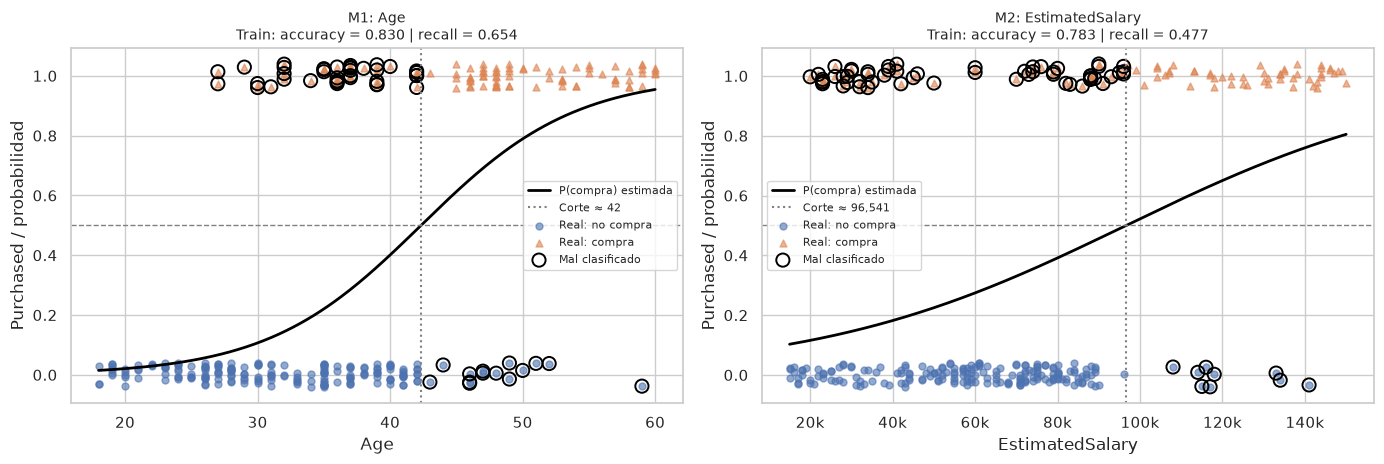

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
rng = np.random.default_rng(0)
for ax, nombre in zip(axes, ['M1: Age', 'M2: EstimatedSalary']):
    vars_, modelo = modelos[nombre]
    col = vars_[0]
    malla = pd.DataFrame({col: np.linspace(X_train[col].min(), X_train[col].max(), 400)})
    p = modelo.predict_proba(malla)[:, 1]
    ax.plot(malla[col], p, color='black', lw=2, label='P(compra) estimada')
    ax.axhline(0.5, color='grey', ls='--', lw=1)
    corte = malla[col][np.argmin(np.abs(p - 0.5))]
    if p.min() < 0.5 < p.max():
        ax.axvline(corte, color='grey', ls=':', lw=1.5, label=f'Corte ≈ {corte:,.0f}')

    pred = modelo.predict(X_train[vars_])
    jitter = rng.uniform(-0.04, 0.04, len(y_train))
    for clase in (0, 1):
        m = (y_train == clase).values
        ax.scatter(X_train.loc[m, col], y_train[m] + jitter[m], c=PALETA[clase],
                   marker=MARCAS[clase], alpha=0.6, s=25, label=f'Real: {"compra" if clase else "no compra"}')
    mal = pred != y_train.values
    ax.scatter(X_train.loc[mal, col], y_train[mal] + jitter[mal], marker='o', facecolors='none',
               edgecolors='black', linewidths=1.4, s=90, label='Mal clasificado')
    acc, rec = accuracy_score(y_train, pred), recall_score(y_train, pred)
    ax.set_title(f'{nombre}\nTrain: accuracy = {acc:.3f} | recall = {rec:.3f}', fontsize=10)
    ax.set_xlabel(col); ax.set_ylabel('Purchased / probabilidad')
    ax.legend(fontsize=8, loc='center right' if col == 'Age' else 'center left')
axes[1].xaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}k')
plt.tight_layout()
plt.show()

**Interpretación:**
- **M1 (Age).** El corte está en torno a los **42 años**: por encima predice "compra" y por debajo "no compra". Acierta el 83 % en Train, pero falla en dos grupos muy concretos. Por un lado, los **jóvenes con salario alto que sí compran** (los triángulos con anillo arriba a la izquierda): el modelo no puede verlos porque no conoce el salario. Por otro, los no compradores de 43 a 52 años. Su recall es 0,654: se le escapa uno de cada tres compradores.
- **M2 (EstimatedSalary).** Corte en torno a **96.500**. Es el peor modelo (accuracy 0,783, recall 0,477). Clasifica como "no compra" a todo el que gane menos de ese corte, así que pierde a todos los compradores de salario bajo o medio (la fila de triángulos con anillo a la izquierda), entre ellos el grupo de mayores con salario bajo que vimos en el EDA. La sigmoide sube despacio, señal de que el salario por sí solo separa mal.
- **Conclusión:** cada variable por separado deja fuera un grupo de compradores que la otra sí identifica. Hay que combinarlas.

### Modelos con Age y EstimatedSalary: de la frontera recta a la curva

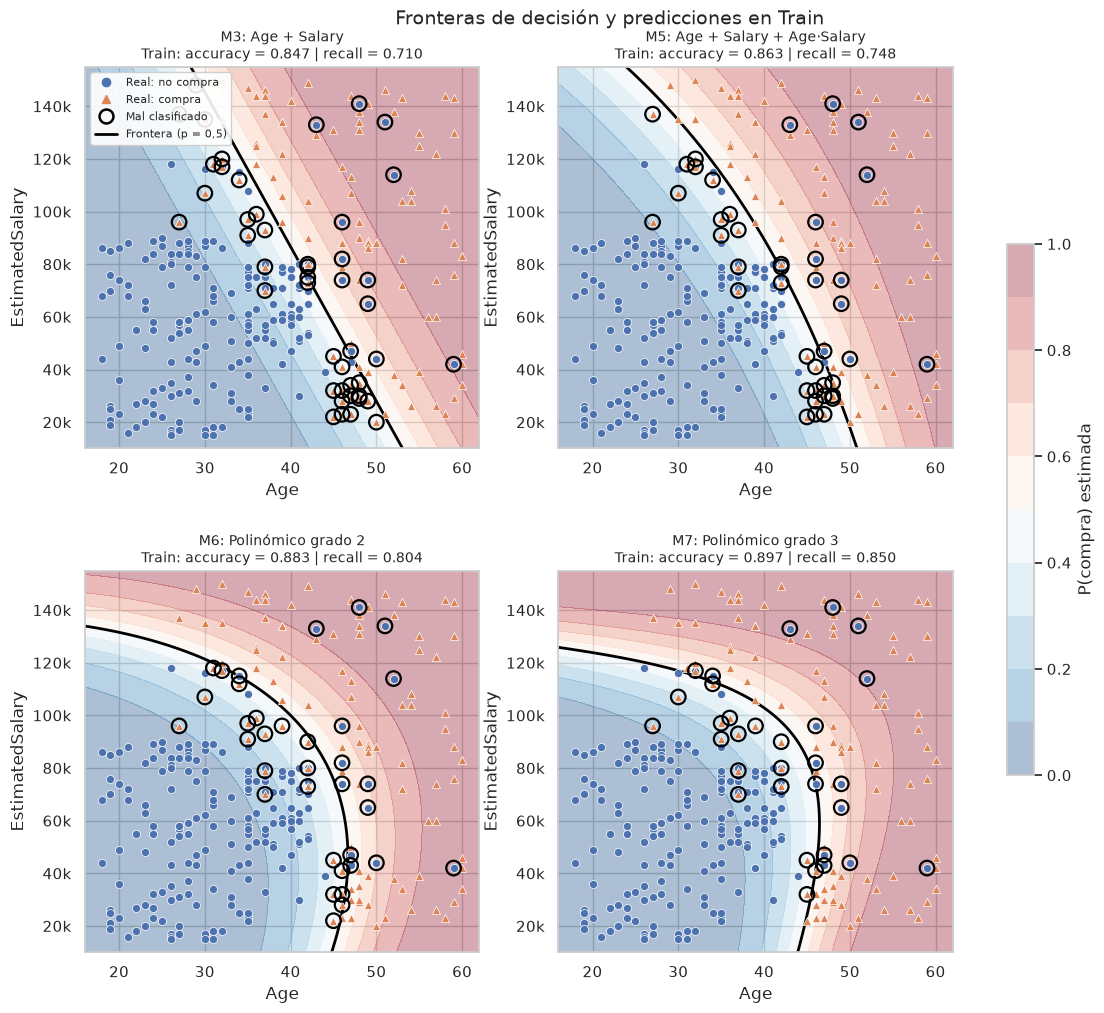

In [18]:
nombres_2d = ['M3: Age + Salary', 'M5: Age + Salary + Age·Salary',
              'M6: Polinómico grado 2', 'M7: Polinómico grado 3']
fig, axes = plt.subplots(2, 2, figsize=(14, 11.5), gridspec_kw={'hspace': 0.32})
for ax, nombre in zip(axes.ravel(), nombres_2d):
    vars_, modelo = modelos[nombre]
    cf = frontera_2d(ax, modelo, vars_, X_train, y_train, titulo=nombre)
leyenda_puntos(axes[0, 0])
fig.colorbar(cf, ax=axes, shrink=0.6, label='P(compra) estimada')
fig.suptitle('Fronteras de decisión y predicciones en Train', fontsize=14, y=0.93)
plt.show()

**Interpretación, modelo a modelo:**
- **M3 (lineal).** La frontera es una **recta** inclinada: a más edad, menos salario hace falta para predecir compra. Se ve claramente el problema anticipado en el EDA: hay un **grupo de errores abajo a la derecha** (compradores de 45-50 años con salario de 20.000 a 40.000) que la recta deja del lado "no compra". También falla en la zona joven con salario alto. Recall de 0,710.
- **M5 (con interacción Age·Salary).** La frontera ya se **curva** un poco y mejora algo (41 errores, recall 0,748). Pero sigue sin "doblar la esquina" en la zona de salarios bajos.
- **M6 (grado 2).** La frontera tiene la **forma de esquina redondeada** que veíamos en el pairplot. Es casi horizontal arriba (en torno a 110.000-130.000 de salario, los jóvenes con mucho salario compran) y casi vertical a la derecha (en torno a 45-47 años, compran los mayores aunque ganen poco). Recupera buena parte del grupo de compradores mayores con salario bajo: 35 errores y recall de 0,804.
- **M7 (grado 3).** La forma es muy parecida a la de M6, algo más ajustada en la esquina (31 errores, recall de 0,850). Que la frontera **no se vuelva extraña** (sin islas ni curvas raras) es buena señal: de momento no hay un sobreajuste evidente. Aun así, la diferencia con M6 es de solo 4 usuarios en Train, una mejora pequeña que debe confirmarse con validación cruzada y Test.
- **En todos los modelos** quedan errores en la banda de 35-45 años y salario de 60.000 a 90.000. Ahí las dos clases están realmente mezcladas y ningún modelo con estas variables puede separarlas: es el error que no se puede eliminar con estos datos.

### Modelo con Gender (M4)
Al tener tres variables, dibujamos la frontera en el plano Age-Salary dos veces: fijando `Gender = 0` (mujeres) y `Gender = 1` (hombres). En cada panel solo aparecen los usuarios de ese género.

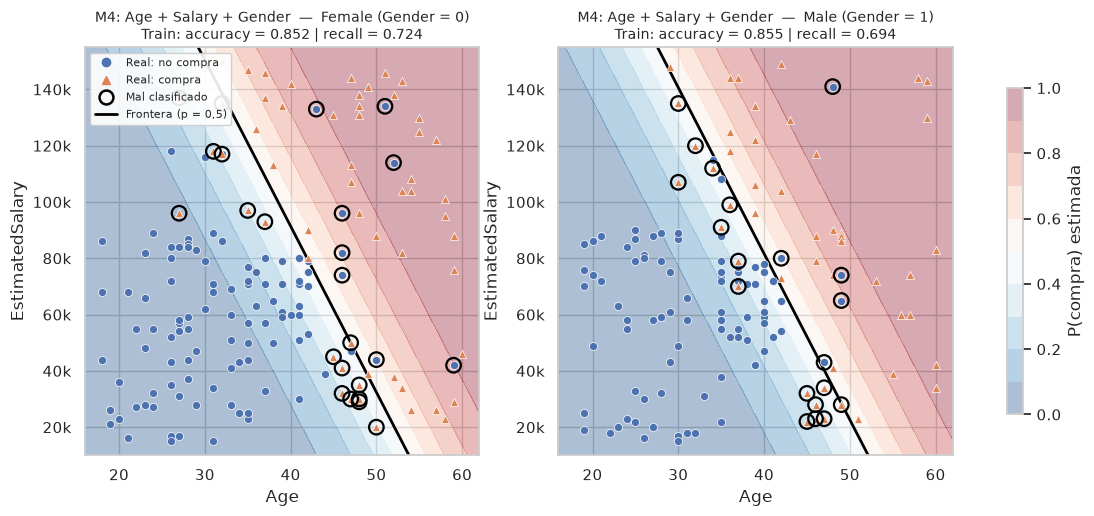

Coeficientes de M4 (variables estandarizadas):
Age                2.166
EstimatedSalary    1.216
Gender             0.168
dtype: float64


In [19]:
vars_, modelo = modelos['M4: Age + Salary + Gender']
fig, axes = plt.subplots(1, 2, figsize=(14, 5.3))
for ax, g, etiqueta in zip(axes, [0, 1], ['Female', 'Male']):
    m = (X_train['Gender'] == g).values
    cf = frontera_2d(ax, modelo, vars_, X_train[m], y_train[m], gender=g,
                     titulo=f'M4: Age + Salary + Gender  —  {etiqueta} (Gender = {g})')
leyenda_puntos(axes[0])
fig.colorbar(cf, ax=axes, shrink=0.8, label='P(compra) estimada')
plt.show()

coef = pd.Series(modelo.named_steps['logreg'].coef_[0],
                 index=modelo.named_steps['poly'].get_feature_names_out(vars_))
print('Coeficientes de M4 (variables estandarizadas):')
print(coef.round(3))

**Interpretación:**
- Las dos fronteras son **prácticamente la misma recta**, apenas desplazada. Eso indica que `Gender` casi no cambia la predicción.
- Con las variables estandarizadas, el coeficiente de `Gender` (≈ 0,17) es mucho menor que el de `Age` (≈ 2,17) y el de `EstimatedSalary` (≈ 1,22).
- Un detalle curioso: el coeficiente es **positivo** (favorece algo a los hombres), aunque en bruto compran algo más las mujeres (37,7 % frente a 33,7 %). Cuando un signo cambia así al ajustar por edad y salario, suele ser señal de que el efecto es ruido y no algo real. Esto refuerza la conclusión del EDA.
- M4 solo mejora a M3 en 2 aciertos en Train (44 errores frente a 46), con la misma frontera recta y los mismos problemas. **No compensa añadir `Gender`.**

### Distribución de la probabilidad predicha en Train
Otra forma de ver las predicciones: cuanto más se separen los histogramas de las dos clases, y menos usuarios queden cerca de 0,5, mejor discrimina el modelo.

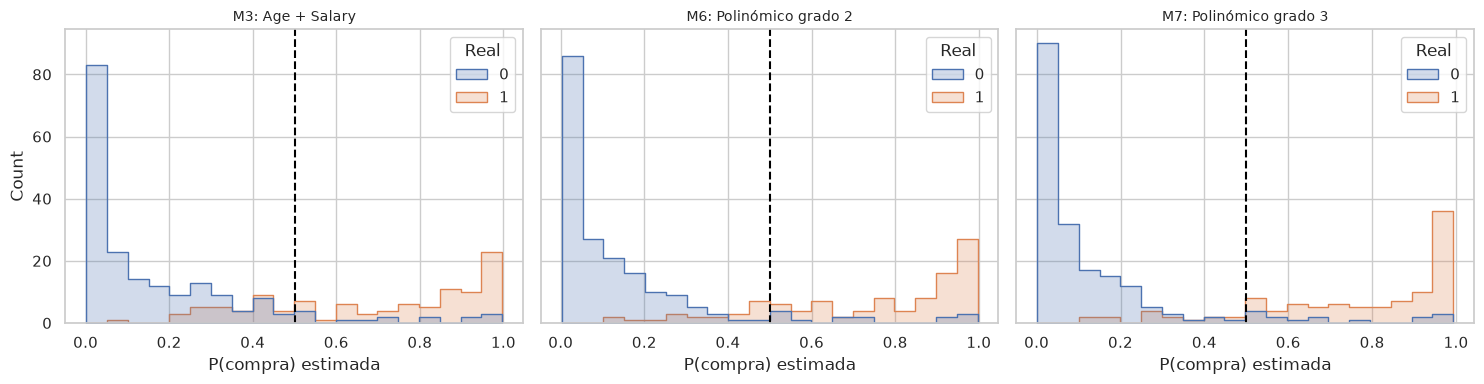

In [20]:
# Distribución de la probabilidad predicha en Train: cuanto más separadas las dos
# distribuciones, mejor discrimina el modelo. La línea vertical es el umbral 0,5.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, nombre in zip(axes, ['M3: Age + Salary', 'M6: Polinómico grado 2', 'M7: Polinómico grado 3']):
    vars_, modelo = modelos[nombre]
    prob = modelo.predict_proba(X_train[vars_])[:, 1]
    sns.histplot(x=prob, hue=y_train.values, palette=PALETA, bins=20, element='step',
                 ax=ax, hue_order=[0, 1])
    ax.axvline(0.5, color='black', ls='--')
    ax.set_title(nombre, fontsize=10); ax.set_xlabel('P(compra) estimada')
    ax.get_legend().set_title('Real')
plt.tight_layout()
plt.show()

**Interpretación:**
- En **M3** muchos compradores reales (naranja) reciben probabilidades entre 0,1 y 0,5, y quedan clasificados como "no compra". Son los falsos negativos que bajan el recall.
- En **M6** y **M7** esa cola naranja a la izquierda del umbral se reduce mucho y los compradores se acumulan cerca de 1. El modelo está más seguro *y* acierta más.
- En los tres quedan algunos no compradores (azul) con probabilidades altas. Son los usuarios de la zona mezclada que ya veíamos en las fronteras.

### Conclusión de la parte gráfica
Los gráficos confirman lo que anticipaba el EDA: **la frontera real entre compradores y no compradores es curva**. Los modelos lineales (M1-M4) fallan de forma sistemática con los compradores mayores de salario bajo y los modelos polinómicos (M6, M7) los recuperan. `Gender` no aporta. Entre M6 y M7 la diferencia visual y en Train es pequeña. **La elección final debe salir de la validación cruzada y de Test** (apartado de Pablo). Si la diferencia ahí también es pequeña, la sencillez juega a favor de M6.